# Practical 3: Simple and Multiple Linear Regression

*Teacher-demo version.* Cells marked **ORIGINAL** are your repository notebook, unchanged. Cells marked **ADDED** are new: input experiments with real outputs, viva questions and common errors. Original file: `Simple_and_Multiple_Linear_Regression_Experiment.ipynb`

**A. Aim:** To implement Simple Linear Regression using NumPy and Multiple Linear Regression using Scikit-learn, plot regression results and residuals, and calculate RMSE and R-squared.

**How to run (every practical)**

1. Install Python 3.10+ and Jupyter, then the libraries: `pip install numpy matplotlib scikit-learn jupyter`
2. Open a terminal / Anaconda Prompt in the folder containing this file and type `jupyter notebook`. Click this notebook.
3. Run cells one by one with **Shift + Enter** (or **Kernel -> Restart & Run All**). Run the cells in order - later cells need variables made by earlier ones.
4. To demonstrate a different result: edit the value on the line marked `# <-- CHANGED` in an experiment cell (or edit the same line in the original cell), then run that cell again. Run **Cell -> Run All** if later cells depend on it.
5. To print: **Ctrl + P** in the browser (as your lab readme suggests).

*Libraries needed here:* numpy, matplotlib, scikit-learn

---
## B / C. ORIGINAL PROGRAM AND ORIGINAL OUTPUT (unchanged cells follow)

<a href="https://colab.research.google.com/github/priyasathe123/ML-Practical-s/blob/main/Simple_and_Multiple_Linear_Regression_Experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment: Simple and Multiple Linear Regression

**Aim:** To implement Simple Linear Regression using NumPy and Multiple Linear Regression using Scikit-learn, plot regression results and residuals, and calculate RMSE and R².

**Software required:** Python, NumPy, Matplotlib, Scikit-learn

**Learning outcomes:**
- Understand simple and multiple linear regression.
- Fit a regression model and predict output values.
- Visualize actual values, predicted values and residuals.
- Evaluate a regression model using RMSE and R².

>


## Part A: Simple Linear Regression using NumPy

In simple linear regression, one input variable (X) is used to predict one output variable (Y).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Input data
X = np.array([1, 2, 3, 4, 5])
Y = np.array([20, 30, 40, 50, 60])

# Find slope and intercept
slope, intercept = np.polyfit(X, Y, 1)

# Predict Y values
Y_pred = slope * X + intercept

# Calculate RMSE
rmse = np.sqrt(np.mean((Y - Y_pred) ** 2))

# Calculate R-squared
ss_total = np.sum((Y - np.mean(Y)) ** 2)
ss_error = np.sum((Y - Y_pred) ** 2)
r2 = 1 - (ss_error / ss_total)

print("Slope:", slope)
print("Intercept:", intercept)
print("Predicted values:", Y_pred)
print("RMSE:", rmse)
print("R-squared:", r2)

Slope: 10.000000000000002
Intercept: 10.00000000000001
Predicted values: [20. 30. 40. 50. 60.]
RMSE: 1.4210854715202004e-14
R-squared: 1.0


### Plot regression line and residuals

A residual is the difference between an actual value and its predicted value. The vertical dashed lines show these residuals.

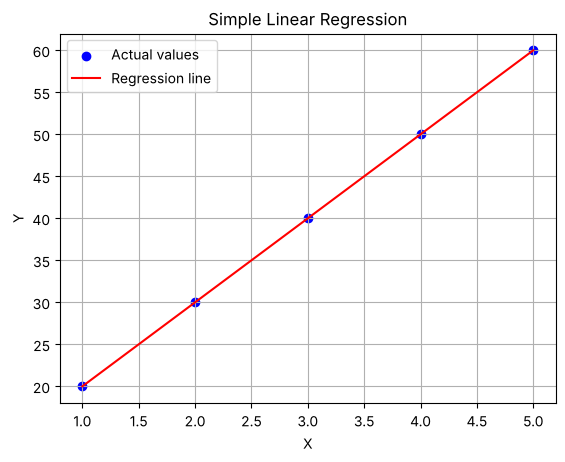

In [2]:
plt.scatter(X, Y, color="blue", label="Actual values")
plt.plot(X, Y_pred, color="red", label="Regression line")

# Show residuals
for i in range(len(X)):
    plt.plot([X[i], X[i]], [Y[i], Y_pred[i]], "k--")

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Simple Linear Regression")
plt.legend()
plt.grid()
plt.show()

### Expected result

- Slope = 10
- Intercept = 10
- Predicted values = [20, 30, 40, 50, 60]
- RMSE = 0
- R² = 1

The data points lie exactly on the regression line, so the prediction error is zero.


## Part B: Multiple Linear Regression using Scikit-learn

Multiple linear regression uses two or more input variables to predict one output variable. Here, marks are predicted using study hours and attendance.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Input data: [Study Hours, Attendance]
X = np.array([
    [1, 60],
    [2, 65],
    [3, 70],
    [4, 75],
    [5, 80],
    [6, 85],
    [7, 90]
])

# Output data: Marks
Y = np.array([40, 45, 50, 55, 65, 70, 80])

# Create and train the model
model = LinearRegression()
model.fit(X, Y)

# Predict marks
Y_pred = model.predict(X)

# Calculate RMSE and R-squared
rmse = np.sqrt(mean_squared_error(Y, Y_pred))
r2 = r2_score(Y, Y_pred)

print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)
print("Predicted marks:", Y_pred)
print("RMSE:", rmse)
print("R-squared:", r2)

Intercept: -38.45467032967027
Coefficients: [0.25412088 1.2706044 ]
Predicted marks: [38.03571429 44.64285714 51.25       57.85714286 64.46428571 71.07142857
 77.67857143]
RMSE: 1.7127969726116872
R-squared: 0.9834770114942528


### Plot actual and predicted values

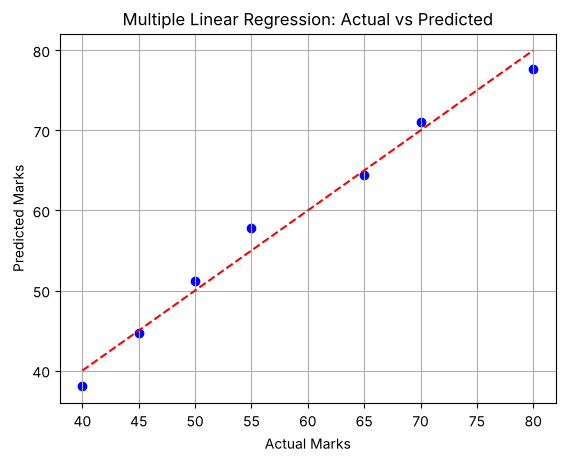

In [4]:
plt.scatter(Y, Y_pred, color="blue")
plt.plot([min(Y), max(Y)], [min(Y), max(Y)], "r--")

plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")
plt.title("Multiple Linear Regression: Actual vs Predicted")
plt.grid()
plt.show()

### Plot residuals

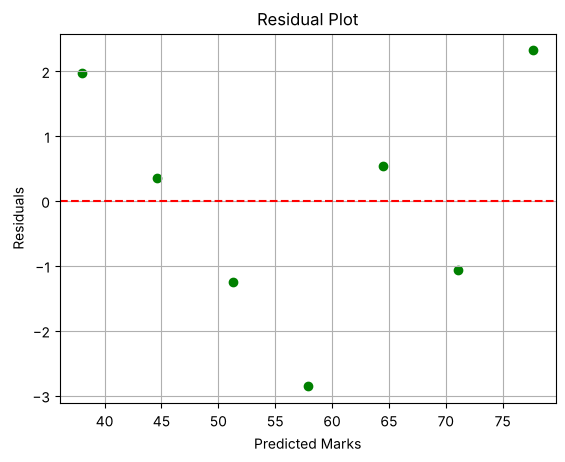

In [5]:
residuals = Y - Y_pred

plt.scatter(Y_pred, residuals, color="green")
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Marks")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.grid()
plt.show()

## Observations

1. Simple Linear Regression uses one independent variable.
2. Multiple Linear Regression uses more than one independent variable.
3. The regression line represents the relationship between input and output.
4. Residuals show the difference between actual and predicted values.
5. Lower RMSE indicates smaller prediction errors.
6. R² closer to 1 indicates that the model explains more variation in the output.

## Result

Simple Linear Regression was implemented using NumPy and Multiple Linear Regression was implemented using Scikit-learn. Regression plots and residual plots were generated, and model performance was evaluated using RMSE and R².


---
## D / E / F. INPUT EXPERIMENTS (ADDED)
Each experiment cell is **self-contained** (it re-creates what it needs), so you can run any experiment on its own. Lines ending in `# <-- CHANGED (original: ...)` show exactly what was edited; `# ADDED line` marks new helper lines.

### D. Input Experiment 1 - Part A: noisy data

**Changed input:** `Y = [20,30,40,50,60]` -> `[22,29,41,48,63]`

**Where in the original notebook:** edit the line(s) shown as CHANGED in the original code cell #1 (section *Part A: Simple Linear Regression using NumPy*).

Slope: 10.100000000000001
Intercept: 10.3
Predicted values: [20.4 30.5 40.6 50.7 60.8]
RMSE: 1.849324200890691
R-squared: 0.9835133050520632


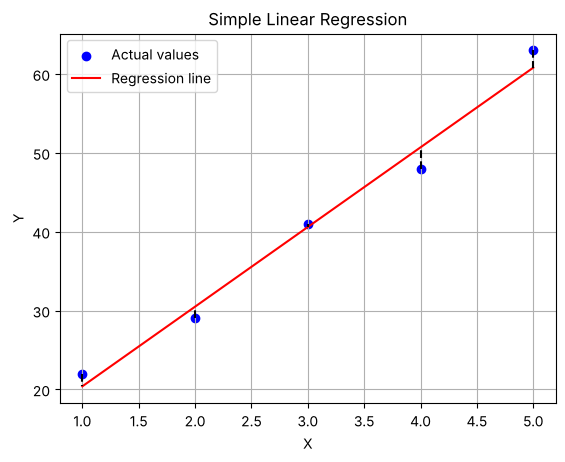

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Input data
X = np.array([1, 2, 3, 4, 5])
Y = np.array([22, 29, 41, 48, 63])  # <-- CHANGED (original: Y = np.array([20, 30, 40, 50, 60]))

# Find slope and intercept
slope, intercept = np.polyfit(X, Y, 1)

# Predict Y values
Y_pred = slope * X + intercept

# Calculate RMSE
rmse = np.sqrt(np.mean((Y - Y_pred) ** 2))

# Calculate R-squared
ss_total = np.sum((Y - np.mean(Y)) ** 2)
ss_error = np.sum((Y - Y_pred) ** 2)
r2 = 1 - (ss_error / ss_total)

print("Slope:", slope)
print("Intercept:", intercept)
print("Predicted values:", Y_pred)
print("RMSE:", rmse)
print("R-squared:", r2)

plt.scatter(X, Y, color="blue", label="Actual values")
plt.plot(X, Y_pred, color="red", label="Regression line")

# Show residuals
for i in range(len(X)):
    plt.plot([X[i], X[i]], [Y[i], Y_pred[i]], "k--")

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Simple Linear Regression")
plt.legend()
plt.grid()
plt.show()

**Actual output explained**

**What changed (Part A):** `Y` now has noise: `[22, 29, 41, 48, 63]`. Slope 10.1, intercept 10.3, fitted values `[20.4, 30.5, 40.6, 50.7, 60.8]`, **RMSE 1.849**, **R^2 0.9835** (originally RMSE 0 and R^2 1).

**Why:** the points no longer lie exactly on a line, so residuals (the dashed vertical lines in the graph) are non-zero. R^2 stays close to 1 because the trend is still almost linear.

### E. Input Experiment 2 - Part A: downward trend + predict a new X

**Changed input:** `Y = [20,30,40,50,60]` -> `[90,75,60,45,30]`; predict for X = 6

**Where in the original notebook:** edit the line(s) shown as CHANGED in the original code cell #1 (section *Part A: Simple Linear Regression using NumPy*).

Slope: -15.000000000000009
Intercept: 105.00000000000004
Predicted values: [90. 75. 60. 45. 30.]
RMSE: 1.9328852131274406e-14
R-squared: 1.0
Predicted Y for X = 6: 14.999999999999986


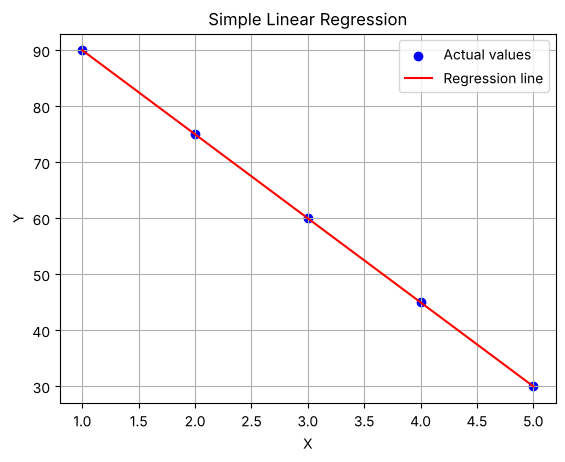

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Input data
X = np.array([1, 2, 3, 4, 5])
Y = np.array([90, 75, 60, 45, 30])  # <-- CHANGED (original: Y = np.array([20, 30, 40, 50, 60]))

# Find slope and intercept
slope, intercept = np.polyfit(X, Y, 1)

# Predict Y values
Y_pred = slope * X + intercept

# Calculate RMSE
rmse = np.sqrt(np.mean((Y - Y_pred) ** 2))

# Calculate R-squared
ss_total = np.sum((Y - np.mean(Y)) ** 2)
ss_error = np.sum((Y - Y_pred) ** 2)
r2 = 1 - (ss_error / ss_total)

print("Slope:", slope)
print("Intercept:", intercept)
print("Predicted values:", Y_pred)
print("RMSE:", rmse)
print("R-squared:", r2)

print("Predicted Y for X = 6:", slope * 6 + intercept)   # ADDED line

plt.scatter(X, Y, color="blue", label="Actual values")
plt.plot(X, Y_pred, color="red", label="Regression line")

# Show residuals
for i in range(len(X)):
    plt.plot([X[i], X[i]], [Y[i], Y_pred[i]], "k--")

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Simple Linear Regression")
plt.legend()
plt.grid()
plt.show()

**Actual output explained**

**What changed (Part A):** `Y = [90, 75, 60, 45, 30]` (decreasing). The slope is **-15** and the intercept **105**; prediction for X = 6 is **15**. RMSE is about 1e-14 and R^2 = 1.

**Why:** the data are exactly Y = -15X + 105, so the line fits perfectly. A negative slope means Y falls as X rises. The tiny RMSE (1.9e-14 instead of 0) and slope -15.000000000000009 are floating-point round-off, not real error - the same happens in the original notebook on newer NumPy versions.

### F. Input Experiment 3 - Part B: different marks + predict a new student

**Changed input:** `Y` marks -> `[45,40,60,52,75,66,88]`; predict for 8 hours, 95% attendance

**Where in the original notebook:** edit the line(s) shown as CHANGED in the original code cell #3 (section *Part B: Multiple Linear Regression using Scikit-learn*).

Intercept: -41.18131868131862
Coefficients: [0.26923077 1.34615385]
Predicted marks: [39.85714286 46.85714286 53.85714286 60.85714286 67.85714286 74.85714286
 81.85714286]
RMSE: 7.139999428342744
R-squared: 0.793587836721203
Predicted marks for 8 study hours, 95% attendance: [88.85714286]


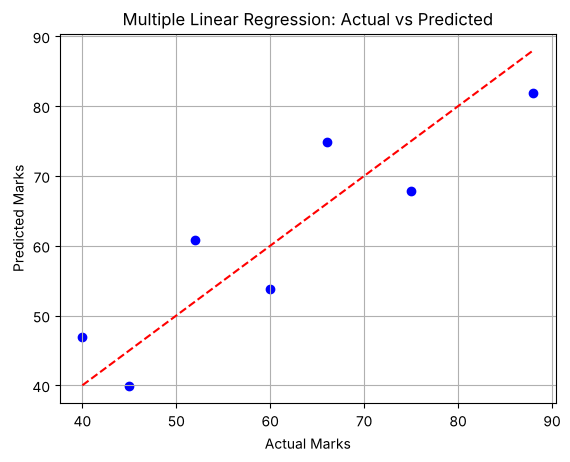

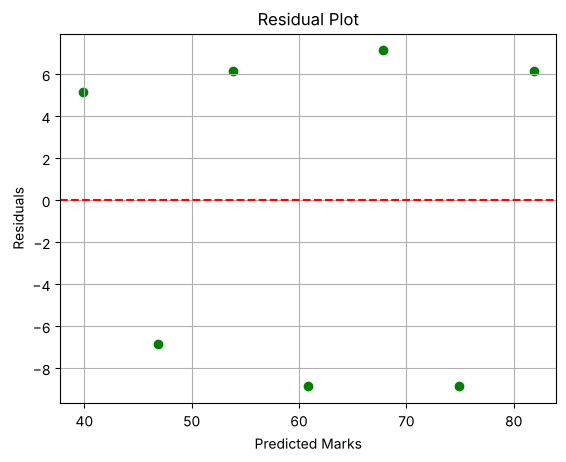

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Input data: [Study Hours, Attendance]
X = np.array([
    [1, 60],
    [2, 65],
    [3, 70],
    [4, 75],
    [5, 80],
    [6, 85],
    [7, 90]
])

# Output data: Marks
Y = np.array([45, 40, 60, 52, 75, 66, 88])  # <-- CHANGED (original: Y = np.array([40, 45, 50, 55, 65, 70, 80]))

# Create and train the model
model = LinearRegression()
model.fit(X, Y)

# Predict marks
Y_pred = model.predict(X)

# Calculate RMSE and R-squared
rmse = np.sqrt(mean_squared_error(Y, Y_pred))
r2 = r2_score(Y, Y_pred)

print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)
print("Predicted marks:", Y_pred)
print("RMSE:", rmse)
print("R-squared:", r2)

print("Predicted marks for 8 study hours, 95% attendance:", model.predict([[8, 95]]))   # ADDED line

plt.scatter(Y, Y_pred, color="blue")
plt.plot([min(Y), max(Y)], [min(Y), max(Y)], "r--")

plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")
plt.title("Multiple Linear Regression: Actual vs Predicted")
plt.grid()
plt.show()

residuals = Y - Y_pred

plt.scatter(Y_pred, residuals, color="green")
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Marks")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.grid()
plt.show()

**Actual output explained**

**What changed (Part B):** marks became `[45, 40, 60, 52, 75, 66, 88]`. Coefficients changed to `[0.2692, 1.3462]` and the intercept to -41.18. **RMSE rose from 1.713 to 7.140** and **R^2 fell from 0.9835 to 0.7936**. The added prediction for a student with 8 hours and 95 % attendance is **88.86 marks**.

**Why:** the new marks do not follow the study-hours trend as closely, so the model explains less of the variation (lower R^2) and the average error is larger (higher RMSE). Note also that in this data Attendance = 5 x Hours + 55 exactly, so the two inputs are perfectly collinear: only the combined effect (about 7.0 marks per extra study hour here) is meaningful, and the split between the two coefficients is not.

---
## G. IMPORTANT VIVA QUESTIONS AND ANSWERS (ADDED)

**Q1. Difference between simple and multiple linear regression?**  
Simple uses one input variable (Y = mX + c). Multiple uses two or more (Y = b0 + b1*X1 + b2*X2 + ...).

**Q2. What does `np.polyfit(X, Y, 1)` do?**  
It fits a degree-1 polynomial (a straight line) by least squares - minimising the sum of squared residuals - and returns the slope and intercept.

**Q3. Write the formulas for RMSE and R-squared.**  
RMSE = sqrt(mean((Y - Y_pred)^2)). R^2 = 1 - SS_error/SS_total, where SS_error = sum((Y - Y_pred)^2) and SS_total = sum((Y - mean(Y))^2).

**Q4. Why are RMSE = 0 and R^2 = 1 in the original Part A?**  
Because the data are exactly Y = 10X + 10, so every residual is zero. (You may see 1.4e-14 instead of 0 because of floating-point round-off.)

**Q5. What is a residual and what should a good residual plot look like?**  
Residual = actual - predicted. A good plot shows points scattered randomly around zero with no pattern; a curve or funnel shape means the model is missing something.

**Q6. What is multicollinearity? Is it present in Part B?**  
It is when input variables are strongly correlated. Yes: Attendance = 5 x Hours + 55 exactly, so the individual coefficients are not uniquely interpretable even though predictions are fine.

**Q7. Can R^2 be negative?**  
Yes, if a model fits worse than simply predicting the mean (for example on test data).

---
## Common errors and solutions (ADDED)

- `ValueError: Expected 2D array, got 1D array` -> `X` for scikit-learn must be 2-D, e.g. `[[8, 95]]`, not `[8, 95]`.
- RMSE prints `1.4e-14` instead of `0.0` -> floating-point round-off, not a bug.
- `LinAlgError` / `Polyfit may be poorly conditioned` -> X values all identical.